# Rutas de acceso y defensa minima en Active Directory

### Proyecto de Matematicas Discretas

Este cuaderno recorre el proyecto paso a paso. Modela un entorno de Active
Directory como un grafo dirigido y aplica algoritmos de teoria de grafos para
pasar del analisis de rutas de acceso al calculo de un plan de defensa minimo.

Una arista `A -> B` significa que quien controla el objeto `A` puede llegar a
controlar `B`. Con esa lectura, toda cadena de aristas hasta un objetivo de alto
valor es una posible ruta de compromiso.

Todo el analisis usa el paquete `grafo_ad`, escrito solo con la biblioteca
estandar de Python. Para las graficas de este cuaderno se usa matplotlib.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt

from grafo_ad.modelo import cargar_json, OBJECTID_DOMAIN_ADMINS

grafo = cargar_json("data/cybersecurity-json-data.json")
print(f"Vertices: {len(grafo)}")
print(f"Aristas:  {len(grafo.aristas)}")
print(f"Objetivos de alto valor: {len(grafo.altos_valores())}")
for n in grafo.altos_valores():
    print("  -", n.nombre)

Vertices: 953
Aristas:  4698
Objetivos de alto valor: 6
  - DOMAIN ADMINS@TestCompany.Local
  - DOMAIN CONTROLLERS@TestCompany.Local
  - ENTERPRISE DOMAIN CONTROLLERS@TestCompany.Local
  - ADMINISTRATORS@TestCompany.Local
  - ENTERPRISE ADMINS@TestCompany.Local
  - TestCompany.Local


## 1. El grafo y su composicion

Los objetos del directorio son los vertices; los accesos entre ellos, las
aristas dirigidas. Veamos como se reparten por tipo.

Objetos por tipo: {'Group': 308, 'Domain': 1, 'GPO': 22, 'OU': 21, 'Computer': 301, 'User': 300}


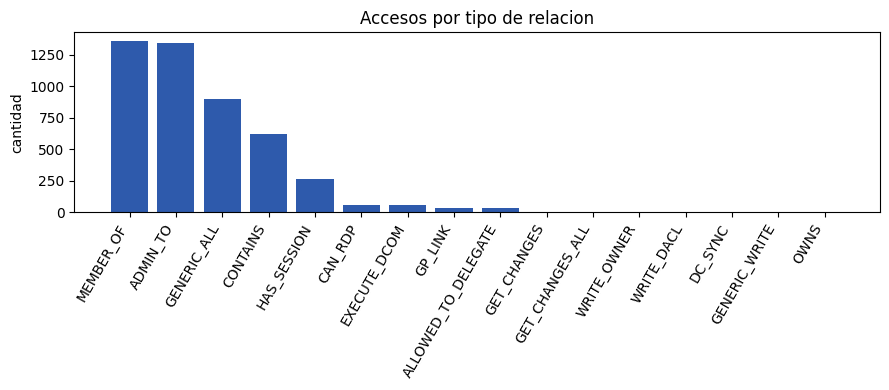

In [2]:
from collections import Counter

tipos_nodo = Counter(n.tipo for n in grafo.nodos.values())
tipos_arista = Counter(a.tipo for a in grafo.aristas)
print("Objetos por tipo:", dict(tipos_nodo))

fig, ax = plt.subplots(figsize=(9, 4))
etiquetas = [t for t, _ in tipos_arista.most_common()]
valores = [c for _, c in tipos_arista.most_common()]
ax.bar(etiquetas, valores, color="#2e5aac")
ax.set_title("Accesos por tipo de relacion")
ax.set_ylabel("cantidad")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

## 2. Alcanzabilidad (BFS)

La busqueda en anchura descubre todos los objetos que un atacante puede
controlar partiendo de una cuenta. Como validacion, el usuario de referencia del
conjunto de datos alcanza exactamente cuatro objetos de alto valor, igual que
reporta la guia del ejemplo original.

In [3]:
from grafo_ad.consultas import alto_valor_alcanzable
from grafo_ad.recorridos import alcanzables

USUARIO = "PiedadFlatley255@TestCompany.Local"
nodo = grafo.buscar_por_nombre(USUARIO)
print(f"{USUARIO} alcanza {len(alcanzables(grafo, nodo.id))} objetos en total.")
print("Objetos de alto valor y su distancia en saltos:")
for objetivo, saltos in alto_valor_alcanzable(grafo, USUARIO):
    print(f"  {objetivo} ({saltos} saltos)")

PiedadFlatley255@TestCompany.Local alcanza 928 objetos en total.
Objetos de alto valor y su distancia en saltos:
  DOMAIN ADMINS@TestCompany.Local (1 saltos)
  TestCompany.Local (2 saltos)
  DOMAIN CONTROLLERS@TestCompany.Local (3 saltos)
  ENTERPRISE DOMAIN CONTROLLERS@TestCompany.Local (3 saltos)


## 3. Camino mas corto (BFS) y de menor esfuerzo (Dijkstra)

BFS da el camino con menos saltos. Si cada acceso tiene un peso que representa su
esfuerzo, Dijkstra da el camino de menor esfuerzo total.

In [4]:
from grafo_ad.recorridos import camino_mas_corto
from grafo_ad.caminos import camino_mas_facil

origen = grafo.buscar_por_nombre(USUARIO)
destino = grafo.buscar_por_objectid("TestCompany.Local-S-1-5-9")  # Enterprise DC

corto = camino_mas_corto(grafo, origen.id, destino.id)
print(f"Camino mas corto: {len(corto)} saltos")
for a in corto:
    print(f"  {grafo.nodos[a.origen].nombre} -[{a.tipo}]-> {grafo.nodos[a.destino].nombre}")

aristas, peso = camino_mas_facil(grafo, origen.id, destino.id)
print(f"\nCamino de menor esfuerzo: peso {peso}, {len(aristas)} saltos")

Camino mas corto: 3 saltos
  PiedadFlatley255@TestCompany.Local -[MEMBER_OF]-> DOMAIN ADMINS@TestCompany.Local
  DOMAIN ADMINS@TestCompany.Local -[ADMIN_TO]-> FLLABDC@TestCompany.Local
  FLLABDC@TestCompany.Local -[MEMBER_OF]-> ENTERPRISE DOMAIN CONTROLLERS@TestCompany.Local

Camino de menor esfuerzo: peso 3, 3 saltos


### Visualizacion del subgrafo y de un camino

Se dibuja el subgrafo de objetos que pueden alcanzar al grupo de administradores
del dominio, usando la disposicion radial del propio paquete, y se resalta en
rojo el camino mas corto del usuario de ejemplo.

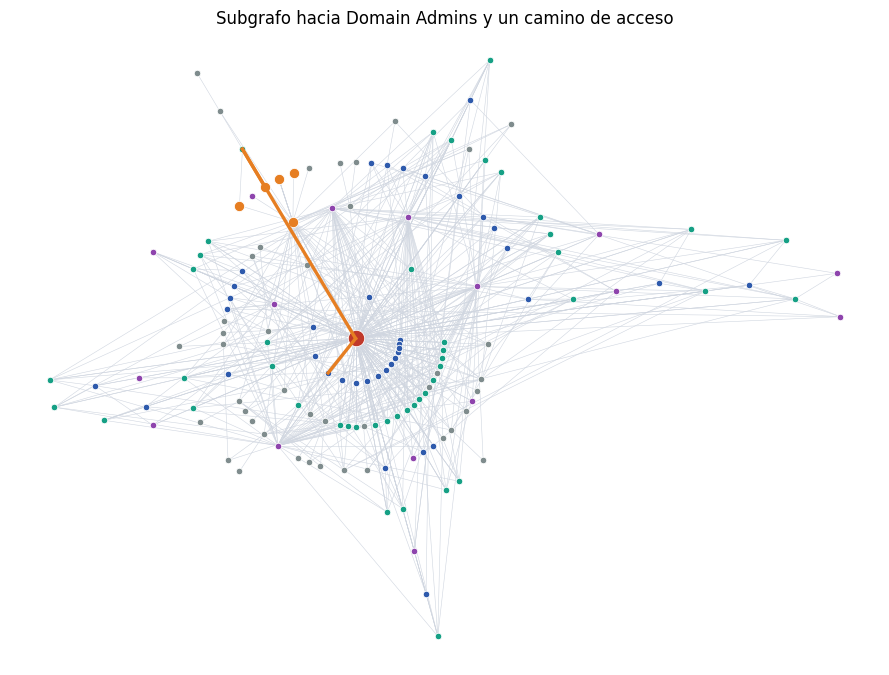

In [5]:
from grafo_ad.trazas import layout_radial, subgrafo_objetivo

COLOR = {"User": "#2e5aac", "Computer": "#16a085", "Group": "#8e44ad",
         "GPO": "#7f8c8d", "OU": "#7f8c8d", "Domain": "#7f8c8d"}

def dibujar(objetivo_id, resaltar=None, color_fn=None, titulo=""):
    permitidos = subgrafo_objetivo(grafo, objetivo_id)
    pos = layout_radial(grafo, objetivo_id, permitidos)
    fig, ax = plt.subplots(figsize=(9, 9))
    for a in grafo.aristas:
        if a.origen in permitidos and a.destino in permitidos:
            x1, y1 = pos[a.origen]; x2, y2 = pos[a.destino]
            ax.plot([x1, x2], [y1, y2], color="#d0d6e0", lw=0.4, zorder=1)
    if resaltar:
        for o, d, col in resaltar:
            if o in pos and d in pos:
                x1, y1 = pos[o]; x2, y2 = pos[d]
                ax.plot([x1, x2], [y1, y2], color=col, lw=2.4, zorder=3)
    for nid in permitidos:
        x, y = pos[nid]
        n = grafo.nodos[nid]
        if color_fn:
            c = color_fn(nid)
        elif nid == objetivo_id:
            c = "#c0392b"
        elif n.alto_valor:
            c = "#e67e22"
        else:
            c = COLOR.get(n.tipo, "#7f8c8d")
        tam = 140 if nid == objetivo_id else (55 if n.alto_valor else 22)
        ax.scatter([x], [y], s=tam, color=c, edgecolors="white", linewidths=0.6, zorder=2)
    ax.set_title(titulo)
    ax.set_aspect("equal"); ax.axis("off")
    plt.tight_layout(); plt.show()

da = grafo.buscar_por_objectid(OBJECTID_DOMAIN_ADMINS)
resaltado = [(a.origen, a.destino, "#e67e22") for a in corto]
dibujar(da.id, resaltar=resaltado, titulo="Subgrafo hacia Domain Admins y un camino de acceso")

## 4. Componentes fuertemente conexas (Tarjan)

Dos objetos estan en la misma componente fuertemente conexa si cada uno alcanza
al otro: un ciclo de control mutuo. Si cae uno, caen todos. Al colapsar cada
componente se obtiene un grafo condensado que es un DAG.

In [6]:
from grafo_ad.componentes import componentes_no_triviales, grafo_condensado

no_triviales = componentes_no_triviales(grafo)
componentes, _, aristas_cond = grafo_condensado(grafo)
print(f"Componentes totales: {len(componentes)}")
print(f"Componentes con control mutuo (tamanio > 1): {len(no_triviales)}")
print(f"Aristas del grafo condensado (DAG): {len(aristas_cond)}")
for comp in sorted(no_triviales, key=len, reverse=True):
    print(f"  componente de {len(comp)} objetos")

Componentes totales: 828
Componentes con control mutuo (tamanio > 1): 2
Aristas del grafo condensado (DAG): 2180
  componente de 125 objetos
  componente de 2 objetos


## 5. Cerradura transitiva de la pertenencia a grupos (Warshall)

La pertenencia a grupos es una relacion binaria. Como los grupos se anidan, los
permisos efectivos dependen de su cerradura transitiva, que se calcula con el
algoritmo de Warshall. Buscamos un usuario cuyos grupos efectivos superen a los
directos por herencia.

In [7]:
from grafo_ad.transitiva import grupos_efectivos

ejemplo = None
for u in grafo.por_tipo("User"):
    directos = {a.destino for a in grafo.salida(u.id) if a.tipo == "MEMBER_OF"}
    efectivos = grupos_efectivos(grafo, u.id)
    if len(efectivos) > len(directos):
        ejemplo = (u, directos, efectivos)
        break

if ejemplo:
    u, directos, efectivos = ejemplo
    print(f"{u.nombre}")
    print(f"  grupos directos:   {len(directos)}")
    print(f"  grupos efectivos:  {len(efectivos)} (incluye los heredados por anidamiento)")
    heredados = efectivos - directos
    print("  heredados:")
    for gid in sorted(heredados, key=lambda g: grafo.nodos[g].nombre):
        print("    -", grafo.nodos[gid].nombre)
else:
    print("No se encontro un usuario con grupos heredados.")

ExieCampisi11@TestCompany.Local
  grupos directos:   5
  grupos efectivos:  6 (incluye los heredados por anidamiento)
  heredados:
    - BIDNESS00204@TestCompany.Local


## 6. Centralidad de intermediacion (Brandes)

Sobre el subgrafo de rutas de acceso al objetivo, la centralidad de
intermediacion mide que objetos actuan como puente en la mayor cantidad de
rutas. Son los de mayor impacto.

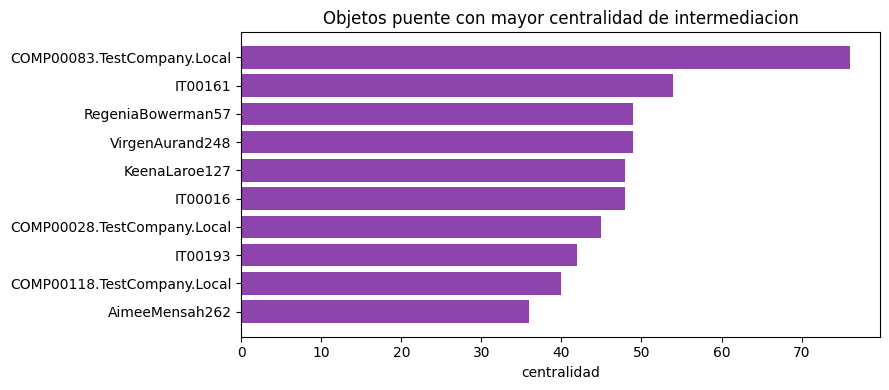

In [8]:
from grafo_ad.centralidad import subgrafo_rutas_ataque, betweenness

rutas = subgrafo_rutas_ataque(grafo, OBJECTID_DOMAIN_ADMINS)
puntajes = betweenness(rutas)
top = sorted(puntajes.items(), key=lambda x: x[1], reverse=True)[:10]

nombres = [grafo.nodos[nid].nombre.split("@")[0] for nid, _ in top]
valores = [v for _, v in top]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(nombres[::-1], valores[::-1], color="#8e44ad")
ax.set_title("Objetos puente con mayor centralidad de intermediacion")
ax.set_xlabel("centralidad")
plt.tight_layout(); plt.show()

## 7. Plan de defensa minimo (flujo maximo y corte minimo)

Esta es la contribucion central. Para aislar un objetivo se busca el conjunto
minimo de accesos a revocar. Se modela como una red de flujo con una superfuente
conectada a los objetos de entrada y un supersumidero tras el objetivo. Los
accesos estructurales no se pueden revocar (capacidad infinita).

Por el **teorema de flujo maximo y corte minimo**, el flujo maximo iguala el
tamanio del corte minimo; por el **teorema de Menger**, ese numero es la cantidad
maxima de rutas disjuntas en aristas. El corte da la lista de accesos a revocar y
los teoremas garantizan que no existe una lista mas corta.

In [9]:
from grafo_ad.cortes import plan_de_defensa
from grafo_ad.riesgo import exposicion, exposicion_tras_corte

fuentes = [n.id for n in grafo.por_tipo("User")]
plan = plan_de_defensa(grafo, fuentes, [da.id])
cortados = {(a["origen"], a["destino"], a["tipo"]) for a in plan["accesos_a_revocar"]}

antes = exposicion(grafo, [da.id], fuentes)
despues = exposicion_tras_corte(grafo, [da.id], cortados, fuentes)

print(f"Corte minimo: {plan['tamanio_corte']} accesos a revocar")
print(f"Verificado (objetivo aislado tras revocar): {plan['verificado']}")
print(f"Exposicion antes:  {antes['fuentes_expuestas']}/{antes['total_fuentes']} "
      f"({antes['fraccion']*100:.1f}%)")
print(f"Exposicion despues: {despues['fuentes_expuestas']}/{despues['total_fuentes']} "
      f"({despues['fraccion']*100:.1f}%)")
print("\nAlgunos accesos a revocar:")
for a in plan["accesos_a_revocar"][:5]:
    print(f"  {a['origen_nombre']} -[{a['tipo']}]-> {a['destino_nombre']}")

Corte minimo: 15 accesos a revocar
Verificado (objetivo aislado tras revocar): True
Exposicion antes:  38/300 (12.7%)
Exposicion despues: 0/300 (0.0%)

Algunos accesos a revocar:
  MyrnaEgnew27@TestCompany.Local -[MEMBER_OF]-> DOMAIN ADMINS@TestCompany.Local
  ShoshanaDeahl233@TestCompany.Local -[MEMBER_OF]-> DOMAIN ADMINS@TestCompany.Local
  DanielleGallery238@TestCompany.Local -[MEMBER_OF]-> DOMAIN ADMINS@TestCompany.Local
  VirgenAurand248@TestCompany.Local -[MEMBER_OF]-> DOMAIN ADMINS@TestCompany.Local
  ReaHardung258@TestCompany.Local -[MEMBER_OF]-> DOMAIN ADMINS@TestCompany.Local


### Visualizacion del corte

El objetivo queda al centro. En rojo, los accesos del corte minimo; en verde, los
objetos que tras revocarlos ya no alcanzan el objetivo.

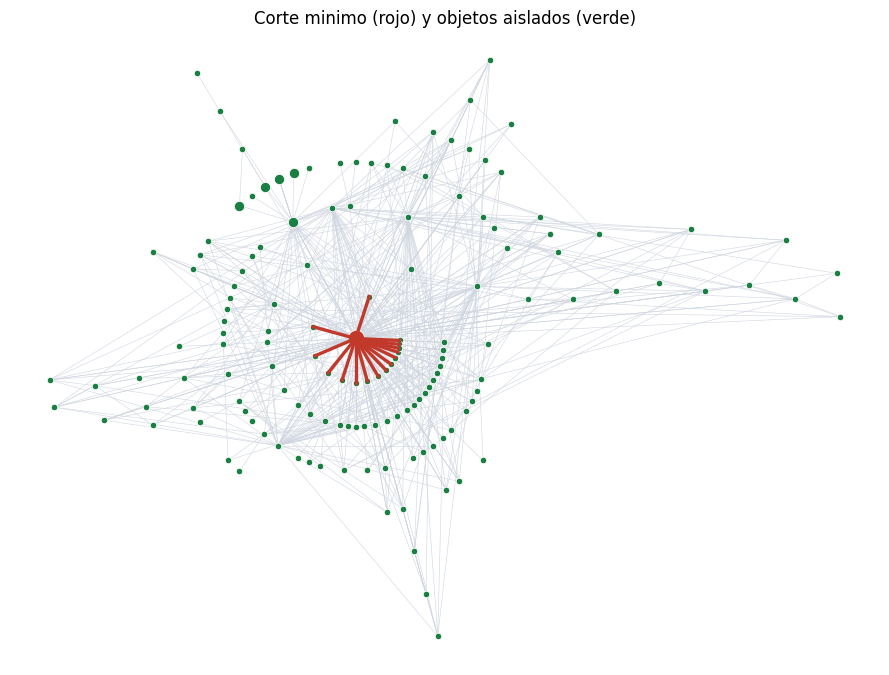

In [10]:
# Objetos que siguen alcanzando el objetivo tras revocar los accesos del corte.
from grafo_ad.riesgo import _alcanzan_a_sin
siguen = _alcanzan_a_sin(grafo, da.id, cortados)

def color_corte(nid):
    if nid == da.id:
        return "#c0392b"
    if nid not in siguen:
        return "#1a7f43"   # ya no alcanza el objetivo
    return "#95a5a6"

resaltar_corte = [(a["origen"], a["destino"], "#c0392b") for a in plan["accesos_a_revocar"]]
dibujar(da.id, resaltar=resaltar_corte, color_fn=color_corte,
        titulo="Corte minimo (rojo) y objetos aislados (verde)")

## Conclusion

El mismo grafo que describe las rutas de un atacante entrega, por un argumento
matematico, el plan de defensa optimo. Para el grupo de administradores del
dominio bastan unos pocos accesos revocados para llevar la exposicion a cero, y
los teoremas de flujo maximo y corte minimo y de Menger garantizan que no hay un
plan mas economico.

Los recorridos responden quien alcanza que, Dijkstra ordena las rutas por
esfuerzo, las componentes fuertemente conexas revelan nucleos de control mutuo,
la cerradura transitiva resuelve los permisos heredados y la centralidad senala
los objetos puente. Todo ello con algoritmos clasicos de teoria de grafos.